# Étude de cas 1 — Jalon 1 : Lire le montant par positions (MLP)
**M2 SDIA – Advanced Artificial Intelligence · ENSET · 2026–2027**

Notebook 100 % MLP : analyse du MLP de référence, confiance et calibration, exploration des hyperparamètres, augmentation par décalages, vérifications théoriques, évaluation finale unique sur le test.

**Protocole** : tous les réglages se font sur la **validation** ; le **test** n'est utilisé qu'une seule fois, à la fin (section 9).

## 0. Environnement et reproductibilité

In [1]:
import os, glob, json, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn
from tensorflow import keras
from tensorflow.keras import layers

SEED = 0
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("Python      :", __import__("sys").version.split()[0])
print("NumPy       :", np.__version__)
print("TensorFlow  :", tf.__version__)
print("Keras       :", keras.__version__)
print("scikit-learn:", sklearn.__version__)
print("GPU         :", tf.config.list_physical_devices("GPU"))

Python      : 3.13.16
NumPy       : 2.1.3
TensorFlow  : 2.21.0
Keras       : 3.13.2
scikit-learn: 1.6.1
GPU         : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Chargement des données

In [2]:
from google.colab import files
files.upload()

def trouver(nom):
    """Cherche uc1_domaineX.npz (tolère un suffixe du type '__1_')."""
    base = nom.replace(".npz", "")
    for d in ["data", ".", "/content", "/content/data"]:
        c = sorted(glob.glob(os.path.join(d, base + "*.npz")))
        if c: return c[0]
    raise FileNotFoundError(nom)

A =(np.load(trouver("/content/uc1_domaineA.npz"), allow_pickle=True))
B =(np.load(trouver("/content/uc1_domaineB.npz"), allow_pickle=True))

for nom, D in [("A", A), ("B", B)]:
    print(f"Domaine {nom} :", {k: D[k].shape for k in D if k.startswith("X_")})

L_MAX = 5
XA = {s: A[f"X_{s}"].astype("float32") / 255.0 for s in ["train", "val", "test"]}
XB = {s: B[f"X_{s}"].astype("float32") / 255.0 for s in ["train", "val", "test"]}
print("Image :", XA["train"].shape[1:], "→", int(np.prod(XA["train"].shape[1:])), "entrées")

Saving uc1_domaineA.npz to uc1_domaineA (1).npz
Saving uc1_domaineB.npz to uc1_domaineB (1).npz
Domaine A : {'X_train': (15000, 32, 128), 'X_val': (3000, 32, 128), 'X_test': (5000, 32, 128)}
Domaine B : {'X_train': (600, 32, 128), 'X_val': (400, 32, 128), 'X_test': (3000, 32, 128)}
Image : (32, 128) → 4096 entrées


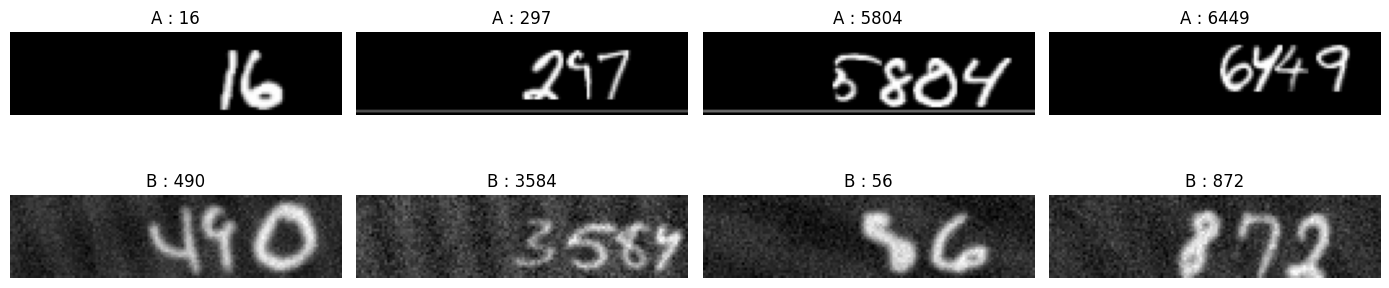

Part de chèques altérés (A, train) : 0.099
Répartition des longueurs (A, train) : {1: 712, 2: 2131, 3: 5108, 4: 4574, 5: 2475}


In [3]:
fig, ax = plt.subplots(2, 4, figsize=(14, 4))
for j in range(4):
    ax[0, j].imshow(XA["train"][j], cmap="gray");
    ax[0, j].set_title(f"A : {A['montant_train'][j]}");
    ax[0, j].axis("off")
    ax[1, j].imshow(XB["train"][j], cmap="gray");
    ax[1, j].set_title(f"B : {B['montant_train'][j]}");
    ax[1, j].axis("off")
plt.tight_layout(); plt.show()
print("Part de chèques altérés (A, train) :", A["altere_train"].mean().round(3))
print("Répartition des longueurs (A, train) :",
      pd.Series(np.char.str_len(A["montant_train"])).value_counts().sort_index().to_dict())

## 2. Encodage par positions, métriques et journal
- 5 sorties softmax à 11 classes ; **position 0 = unités**, position 4 = dizaines de mille ; classe **10 = position vide**.
- **Confiance** = produit des probabilités maximales des 5 têtes.
- **Taux d'automatisation** = plus grande part de chèques (triés par confiance décroissante) dont au moins 99 % des lectures sont exactes.

In [4]:
VIDE = 10

def vers_positions(montants):
    """['16'] -> [[6,1,10,10,10]] (position 0 = unités)."""
    Y = np.full((len(montants), L_MAX), VIDE, dtype="int64")
    for i, m in enumerate(montants):
        for k, c in enumerate(reversed(str(m))):
            Y[i, k] = int(c)
    return Y

def depuis_positions(Y):
    """Inverse : matrice (N, 5) -> tableau de chaînes."""
    out = []
    for row in Y:
        s = "".join(str(d) for d in row[::-1] if d != VIDE)
        out.append(s)
    return np.array(out)

def dict_positions(montants):
    Y = vers_positions(montants)
    return {f"pos{k}": Y[:, k] for k in range(L_MAX)}

def probas(model, X, batch_size=512):
    P = model.predict(X, verbose=0, batch_size=batch_size)
    if isinstance(P, dict):
        return np.stack([P[f"pos{k}"] for k in range(L_MAX)], axis=1)
    return np.stack(P, axis=1)

def lire_positions(model, X):
    """Retourne (montants lus, confiance = produit des max des 5 têtes)."""
    P = probas(model, X)
    lus = depuis_positions(P.argmax(-1))
    conf = P.max(-1).prod(-1)
    return lus, conf

def exactitude_montant(lus, vrais):
    return float(np.mean(np.asarray(lus) == np.asarray(vrais)))

def courbe_automatisation(correct, confiance):
    c = np.asarray(correct, float)[np.argsort(-np.asarray(confiance))]
    rang = np.arange(1, len(c) + 1)
    return rang / len(c), np.cumsum(c) / rang

def taux_automatisation(correct, confiance, cible=0.99):
    part, prec = courbe_automatisation(correct, confiance)
    ok = np.where(prec >= cible)[0]
    return float(part[ok.max()]) if len(ok) else 0.0

# --- journal d'expériences ---
JOURNAL = "journal_experiences.csv"

def journaliser(jalon, nom, params, metriques, remarque=""):
    ligne = {"date": time.strftime("%Y-%m-%d %H:%M:%S"), "jalon": jalon, "essai": nom,
             "params": json.dumps(params, default=str), **metriques, "remarque": remarque}
    df = pd.DataFrame([ligne])
    df.to_csv(JOURNAL, mode="a", header=not os.path.exists(JOURNAL), index=False)
    return ligne

# tests rapides
assert (depuis_positions(vers_positions(np.array(["16", "8", "12345"]))) == np.array(["16", "8", "12345"])).all()
print("Encodage OK :", vers_positions(np.array(["16"]))[0])

Encodage OK : [ 6  1 10 10 10]


## 3. MLP de référence (5 têtes)
Flatten (4 096) → Dense 256 → Dense 128 → 5 têtes softmax de 11 classes.

In [5]:
def construire_mlp(largeurs=(256, 128), dropout=0.0, lr=1e-3, activation="relu"):
    entree = keras.Input(shape=(32, 128), name="image")
    x = layers.Flatten()(entree)
    for i, w in enumerate(largeurs):
        x = layers.Dense(w, activation=activation, name=f"dense{i+1}")(x)
        if dropout > 0:
            x = layers.Dropout(dropout)(x)
    sorties = {f"pos{k}": layers.Dense(11, activation="softmax", name=f"pos{k}")(x) for k in range(L_MAX)}
    m = keras.Model(entree, sorties)
    m.compile(optimizer=keras.optimizers.Adam(lr),
              loss={f"pos{k}": "sparse_categorical_crossentropy" for k in range(L_MAX)},
              metrics={f"pos{k}": "accuracy" for k in range(L_MAX)})
    return m

def decaler(X, max_px, rng):
    """Décalage horizontal aléatoire de -max_px à +max_px pixels (remplissage noir)."""
    out = np.zeros_like(X)
    for i, d in enumerate(rng.integers(-max_px, max_px + 1, len(X))):
        if d >= 0: out[i, :, d:] = X[i, :, :X.shape[2] - d]
        else:      out[i, :, :d] = X[i, :, -d:]
    return out

Ytr, Yva = dict_positions(A["montant_train"]), dict_positions(A["montant_val"])

def entrainer(model, epochs=30, aug_px=0, batch=128, patience=6, verbose=True, seed=SEED):
    """Entraîne époque par époque (nouveau tirage d'augmentation à chaque époque),
    garde les meilleurs poids selon la perte de validation."""
    rng = np.random.default_rng(seed)
    hist = {"loss": [], "val_loss": [], "exact_train": [], "exact_val": []}
    meilleur, best_w, attente = np.inf, model.get_weights(), 0
    sous = rng.choice(len(XA["train"]), 3000, replace=False)   # sous-échantillon pour suivre l'exactitude train
    for ep in range(epochs):
        Xe = decaler(XA["train"], aug_px, rng) if aug_px > 0 else XA["train"]
        h = model.fit(Xe, Ytr, batch_size=batch, epochs=1, verbose=0, shuffle=True)
        ev = model.evaluate(XA["val"], Yva, verbose=0, return_dict=True, batch_size=512)
        hist["loss"].append(h.history["loss"][0]); hist["val_loss"].append(ev["loss"])
        hist["exact_train"].append(exactitude_montant(lire_positions(model, XA["train"][sous])[0], A["montant_train"][sous]))
        hist["exact_val"].append(exactitude_montant(lire_positions(model, XA["val"])[0], A["montant_val"]))
        if verbose:
            print(f"ep {ep+1:02d} loss={hist['loss'][-1]:.3f} val_loss={ev['loss']:.3f} "
                  f"exact_train={hist['exact_train'][-1]:.3f} exact_val={hist['exact_val'][-1]:.3f}")
        if ev["loss"] < meilleur - 1e-4:
            meilleur, best_w, attente = ev["loss"], model.get_weights(), 0
        else:
            attente += 1
            if attente >= patience: break
    model.set_weights(best_w)
    return hist

def tracer(hist, titre=""):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(hist["loss"], label="train");
    ax[0].plot(hist["val_loss"], label="val")
    ax[0].set_title(f"Perte {titre}");
    ax[0].set_xlabel("époque");
    ax[0].legend()
    ax[1].plot(hist["exact_train"], label="train");
    ax[1].plot(hist["exact_val"], label="val")
    ax[1].set_title("Montant exact");
    ax[1].set_xlabel("époque");
    ax[1].legend()
    plt.tight_layout();
    plt.show()

def evaluer_val(model):
    lus, conf = lire_positions(model, XA["val"])
    ok = lus == A["montant_val"]
    return {"exact_val": float(ok.mean()), "auto_val": taux_automatisation(ok, conf)}

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 32, 128)   │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 4096)      │          0 │ image[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense1 (Dense)      │ (None, 256)       │  1,048,832 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense2 (Dense)      │ (None, 128)       │     32,896 │ dense1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos0 (Dense)        │ (None, 11)        │      1,419 │ dense2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos1 (Dense)        │ (None, 11)        │      1,419 │ dense2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos2 (Dense)        │ (None, 11)        │      1,419 │ dense2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos3 (Dense)        │ (None, 11)        │      1,419 │ dense2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos4 (Dense)        │ (None, 11)        │      1,419 │ dense2[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,088,823 (4.15 MB)

 Trainable params: 1,088,823 (4.15 MB)

 Non-trainable params: 0 (0.00 B)

ep 01 loss=8.645 val_loss=7.940 exact_train=0.032 exact_val=0.030
ep 02 loss=7.453 val_loss=7.447 exact_train=0.055 exact_val=0.042
ep 03 loss=6.831 val_loss=7.180 exact_train=0.077 exact_val=0.051
ep 04 loss=6.307 val_loss=7.033 exact_train=0.103 exact_val=0.057
ep 05 loss=5.854 val_loss=7.017 exact_train=0.119 exact_val=0.058
ep 06 loss=5.450 val_loss=7.057 exact_train=0.142 exact_val=0.061
ep 07 loss=5.096 val_loss=7.123 exact_train=0.171 exact_val=0.066
ep 08 loss=4.779 val_loss=7.234 exact_train=0.192 exact_val=0.067
ep 09 loss=4.502 val_loss=7.523 exact_train=0.194 exact_val=0.066
ep 10 loss=4.277 val_loss=7.683 exact_train=0.210 exact_val=0.067
ep 11 loss=4.113 val_loss=7.910 exact_train=0.226 exact_val=0.077


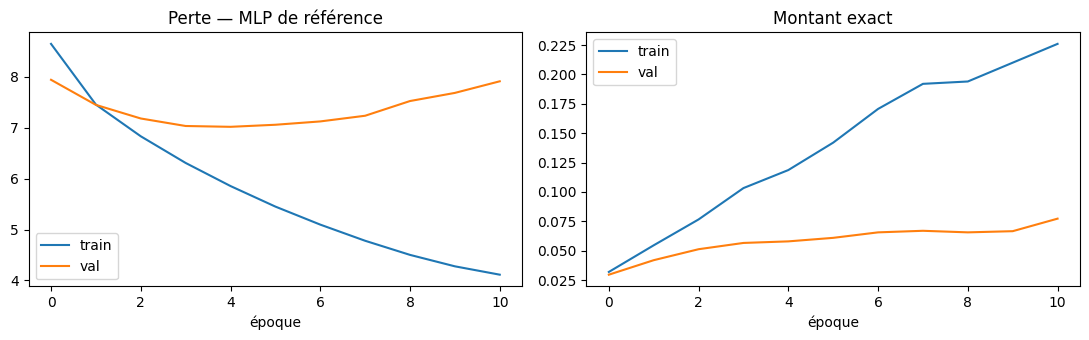

{'exact_val': 0.058, 'auto_val': 0.0003333333333333333}


{'date': '2026-10-29 13:18:03',
 'jalon': 1,
 'essai': 'reference',
 'params': '{"largeurs": [256, 128], "dropout": 0, "lr": 0.001, "aug_px": 0}',
 'exact_val': 0.058,
 'auto_val': 0.0003333333333333333,
 'remarque': 'MLP de référence'}

In [6]:
tf.keras.utils.set_random_seed(SEED)
mlp = construire_mlp()
mlp.summary()
hist_ref = entrainer(mlp, epochs=40)
tracer(hist_ref, "— MLP de référence")
res = evaluer_val(mlp);
print(res)
journaliser(1, "reference", {"largeurs": (256, 128), "dropout": 0, "lr": 1e-3, "aug_px": 0}, res, "MLP de référence")

## 4. Analyse du MLP de référence (question 1)
Exactitude par position (0 = unités) et par longueur de montant, sur la **validation**.

position 0 : 0.447
position 1 : 0.3273
position 2 : 0.3963
position 3 : 0.612
position 4 : 0.837
1 chiffre(s) : 0.5328  (n=137)
2 chiffre(s) : 0.1306  (n=467)
3 chiffre(s) : 0.0345  (n=985)
4 chiffre(s) : 0.0055  (n=907)
5 chiffre(s) : 0.0020  (n=504)


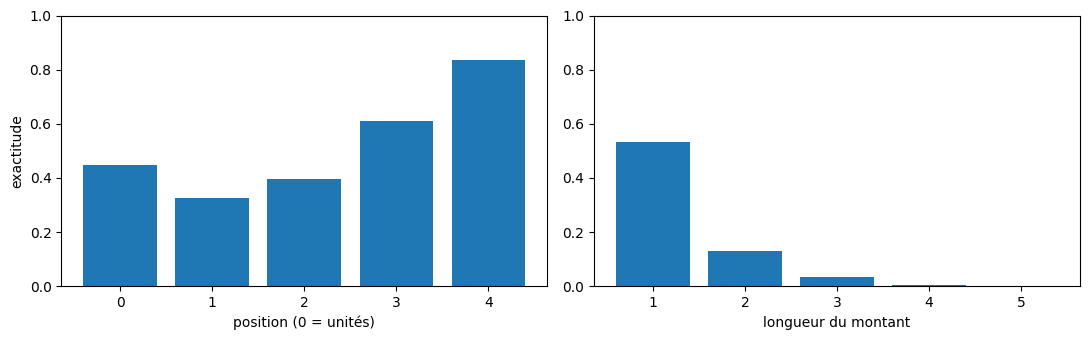

Exactitude selon altération : {0: 0.0589, 1: 0.0491}


In [7]:
P = probas(mlp, XA["val"]); Yv = vers_positions(A["montant_val"])
acc_pos = [np.mean(P[:, k].argmax(-1) == Yv[:, k]) for k in range(L_MAX)]
for k, a in enumerate(acc_pos): print(f"position {k} :", round(a, 4))

lus, conf = lire_positions(mlp, XA["val"])
longueur = np.char.str_len(A["montant_val"])
acc_long = {n: np.mean(lus[longueur == n] == A["montant_val"][longueur == n]) for n in range(1, L_MAX + 1)}
for n, a in acc_long.items(): print(f"{n} chiffre(s) : {a:.4f}  (n={np.sum(longueur == n)})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(range(L_MAX), acc_pos);
ax[0].set_xlabel("position (0 = unités)");
ax[0].set_ylabel("exactitude");
ax[0].set_ylim(0, 1)
ax[1].bar(list(acc_long.keys()), list(acc_long.values()));
ax[1].set_xlabel("longueur du montant");
ax[1].set_ylim(0, 1)
plt.tight_layout();
plt.show()

# Décomposition utile : erreur sur les positions vides vs remplies + effet de l'altération
print("Exactitude selon altération :",
      {int(a): round(float(np.mean(lus[A['altere_val'] == a] == A['montant_val'][A['altere_val'] == a])), 4) for a in [0, 1]})

**Analyse** : Les positions de poids fort (pos3, pos4) sont plus faciles car
souvent vides (classe majoritaire "vide"). Les unités (pos0) sont les plus
difficiles car leur position horizontale varie selon la longueur du montant.
Le MLP n'a pas d'invariance par translation : un même chiffre décalé active
des poids différents.

## 5. Confiance, calibration et seuil (question 2)

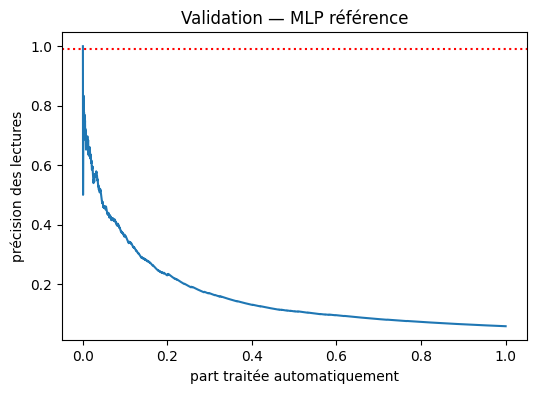

Taux d'automatisation (val) : 0.0003


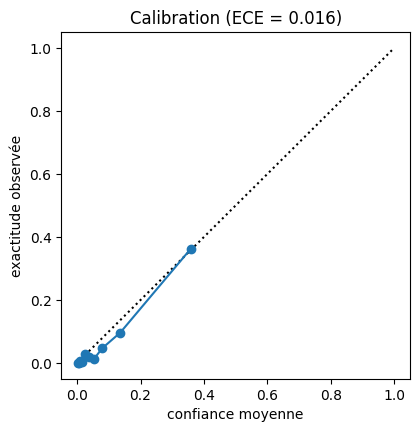

Seuil retenu (val) = 0.9334 → part automatisée = 0.000, précision = 1.0000
Coût : 100.0% des chèques partent vers l'opérateur.


In [8]:
correct_val = lus == A["montant_val"]
part, prec = courbe_automatisation(correct_val, conf)
plt.figure(figsize=(6, 4));
plt.plot(part, prec);
plt.axhline(0.99, color="r", ls=":")
plt.xlabel("part traitée automatiquement");
plt.ylabel("précision des lectures");
plt.title("Validation — MLP référence");
plt.show()
print("Taux d'automatisation (val) :", round(taux_automatisation(correct_val, conf), 4))

def calibration(conf, correct, bins=10):
    edges = np.quantile(conf, np.linspace(0, 1, bins + 1))
    idx = np.clip(np.searchsorted(edges, conf, side="right") - 1, 0, bins - 1)
    c_moy = np.array([conf[idx == b].mean() for b in range(bins)])
    a_moy = np.array([correct[idx == b].mean() for b in range(bins)])
    poids = np.array([np.mean(idx == b) for b in range(bins)])
    ece = float(np.sum(poids * np.abs(c_moy - a_moy)))
    return c_moy, a_moy, ece

c_moy, a_moy, ece = calibration(conf, correct_val)
plt.figure(figsize=(4.5, 4.5));
plt.plot([0, 1], [0, 1], "k:");
plt.plot(c_moy, a_moy, "o-")
plt.xlabel("confiance moyenne");
plt.ylabel("exactitude observée");
plt.title(f"Calibration (ECE = {ece:.3f})");
plt.show()

def seuil_confiance(correct, conf, cible=0.99):
    """Plus petit seuil tel que les chèques de confiance >= seuil ont une précision >= cible (sur la validation)."""
    ordre = np.argsort(-conf);
    c = np.asarray(correct, float)[ordre]
    prec = np.cumsum(c) / np.arange(1, len(c) + 1)
    ok = np.where(prec >= cible)[0]
    return float(conf[ordre][ok.max()]) if len(ok) else 1.0

seuil = seuil_confiance(correct_val, conf)
auto = conf >= seuil
print(f"Seuil retenu (val) = {seuil:.4f} → part automatisée = {auto.mean():.3f}, précision = {correct_val[auto].mean():.4f}")
print(f"Coût : {(~auto).mean():.1%} des chèques partent vers l'opérateur.")

**À rédiger** : la confiance est-elle bien calibrée (sur-confiance du MLP ?) ; le seuil est fixé sur la validation, puis appliqué tel quel au test ; coût = part des chèques renvoyés à l'opérateur. Regardez aussi si les chèques altérés ont une confiance plus faible.

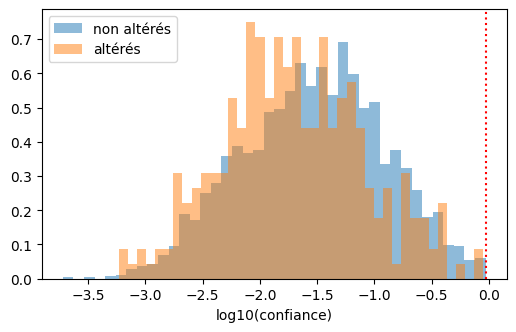

In [9]:
plt.figure(figsize=(6, 3.5))
for a, nom in [(0, "non altérés"), (1, "altérés")]:
    plt.hist(np.log10(conf[A["altere_val"] == a] + 1e-12), bins=40, alpha=.5, label=nom, density=True)
plt.axvline(np.log10(seuil), color="r", ls=":");
plt.xlabel("log10(confiance)");
plt.legend(); plt.show()

## 6. Hyperparamètres : largeur, profondeur, dropout, taux d'apprentissage (question 3)

In [10]:
def essai(nom, largeurs=(256, 128), dropout=0.0, lr=1e-3, aug_px=0, epochs=30, remarque=""):
    tf.keras.utils.set_random_seed(SEED)
    m = construire_mlp(largeurs, dropout, lr)
    h = entrainer(m, epochs=epochs, aug_px=aug_px, verbose=False)
    r = evaluer_val(m)
    r.update(n_params=m.count_params(), epoques=len(h["loss"]),
             ecart_train_val=float(h["exact_train"][int(np.argmin(h["val_loss"]))] - r["exact_val"]))
    journaliser(1, nom, {"largeurs": largeurs, "dropout": dropout, "lr": lr, "aug_px": aug_px}, r, remarque)
    print(f"{nom:28s} exact_val={r['exact_val']:.4f} auto_val={r['auto_val']:.3f} "
          f"écart train-val={r['ecart_train_val']:+.3f} params={r['n_params']:,}")
    return m, h, r

ESSAIS = {}
# --- largeur / profondeur ---
for nom, w in [("largeur 128-64", (128, 64)), ("largeur 512-256", (512, 256)), ("largeur 1024-512", (1024, 512)),
               ("profondeur 1 couche", (256,)), ("profondeur 3 couches", (256, 256, 128))]:
    ESSAIS[nom] = essai(nom, largeurs=w)

largeur 128-64               exact_val=0.0450 auto_val=0.005 écart train-val=+0.047 params=536,247
largeur 512-256              exact_val=0.0710 auto_val=0.008 écart train-val=+0.082 params=2,243,127
largeur 1024-512             exact_val=0.0750 auto_val=0.005 écart train-val=+0.081 params=4,748,343
profondeur 1 couche          exact_val=0.0607 auto_val=0.003 écart train-val=+0.072 params=1,062,967
profondeur 3 couches         exact_val=0.0557 auto_val=0.003 écart train-val=+0.047 params=1,154,615


In [11]:
# --- dropout ---
for d in [0.2, 0.4, 0.5]:
    ESSAIS[f"dropout {d}"] = essai(f"dropout {d}", dropout=d, epochs=40)
# --- taux d'apprentissage ---
for lr in [1e-2, 3e-3, 3e-4, 1e-4]:
    ESSAIS[f"lr {lr}"] = essai(f"lr {lr}", lr=lr, epochs=40, remarque="essai lr")

dropout 0.2                  exact_val=0.0723 auto_val=0.008 écart train-val=+0.097 params=1,088,823
dropout 0.4                  exact_val=0.0717 auto_val=0.002 écart train-val=+0.095 params=1,088,823
dropout 0.5                  exact_val=0.0543 auto_val=0.004 écart train-val=+0.045 params=1,088,823
lr 0.01                      exact_val=0.0303 auto_val=0.001 écart train-val=+0.014 params=1,088,823
lr 0.003                     exact_val=0.0597 auto_val=0.002 écart train-val=+0.047 params=1,088,823
lr 0.0003                    exact_val=0.0777 auto_val=0.006 écart train-val=+0.104 params=1,088,823
lr 0.0001                    exact_val=0.0747 auto_val=0.003 écart train-val=+0.104 params=1,088,823


In [12]:
def journaliser(jalon, nom, params, metriques, remarque=""):
    ligne = {"date": time.strftime("%Y-%m-%d %H:%M:%S"), "jalon": jalon, "essai": nom,
             "params": json.dumps(params, default=str), **metriques, "remarque": remarque}
    nouveau = pd.DataFrame([ligne])
    if os.path.exists(JOURNAL):
        ancien = pd.read_csv(JOURNAL)
        nouveau = pd.concat([ancien, nouveau], ignore_index=True)   # colonnes alignées
    nouveau.to_csv(JOURNAL, index=False)
    return ligne

In [13]:
if os.path.exists(JOURNAL):
    os.remove(JOURNAL)

# essai de référence (variable `res` de la section 3)
journaliser(1, "reference", {"largeurs": (256, 128), "dropout": 0, "lr": 1e-3, "aug_px": 0}, res, "MLP de référence")

# tous les autres essais déjà exécutés
for nom, (m, h, r) in ESSAIS.items():
    journaliser(1, nom, {"essai": nom}, r)

print(pd.read_csv(JOURNAL).shape)

(13, 10)


,essai,exact_val,auto_val,n_params,epoques,ecart_train_val
0,lr 0.0003,0.077667,0.006000,1088823.0,17.0,0.103667
1,largeur 1024-512,0.075000,0.004667,4748343.0,9.0,0.081333
2,lr 0.0001,0.074667,0.002667,1088823.0,31.0,0.103667
3,dropout 0.2,0.072333,0.007667,1088823.0,18.0,0.096667
4,dropout 0.4,0.071667,0.002333,1088823.0,34.0,0.094667
5,largeur 512-256,0.071000,0.008000,2243127.0,10.0,0.082333
6,profondeur 1 couche,0.060667,0.002667,1062967.0,12.0,0.071667
7,lr 0.003,0.059667,0.002333,1088823.0,10.0,0.046667
8,reference,0.058000,0.000333,NaN,NaN,NaN
9,profondeur 3 couches,0.055667,0.002667,1154615.0,10.0,0.046667


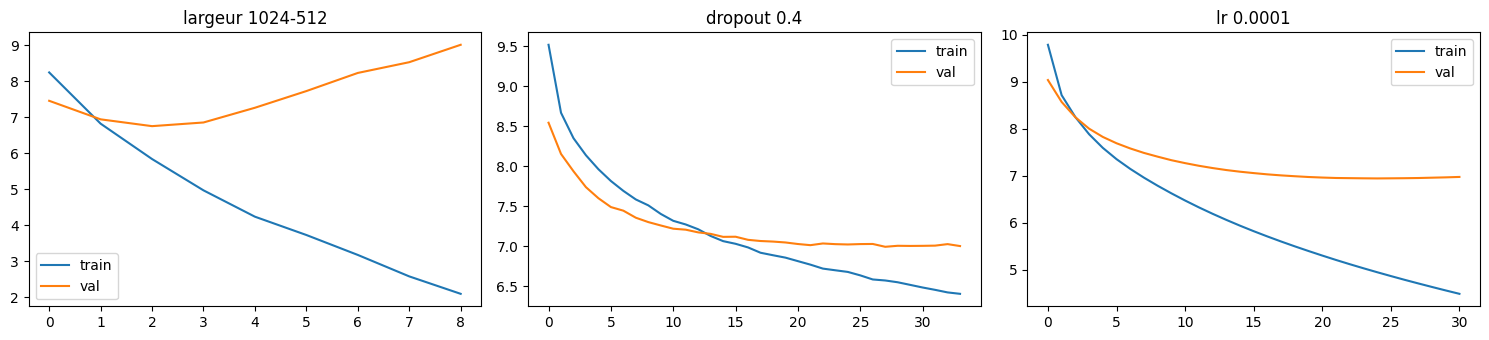

In [14]:
j = pd.read_csv(JOURNAL)   # séparateur virgule par défaut
tab = j[j["jalon"] == 1][["essai", "exact_val", "auto_val", "n_params", "epoques", "ecart_train_val"]] \
        .sort_values("exact_val", ascending=False)
display(tab.reset_index(drop=True))

# courbes d'apprentissage : sous-apprentissage vs sur-apprentissage
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, nom in zip(ax, ["largeur 1024-512", "dropout 0.4", "lr 0.0001"]):
    h = ESSAIS[nom][1]
    a.plot(h["loss"], label="train");
    a.plot(h["val_loss"], label="val")
    a.set_title(nom);
    a.legend()
plt.tight_layout();
plt.show()

## 7. Augmentation par décalages horizontaux (question 4)

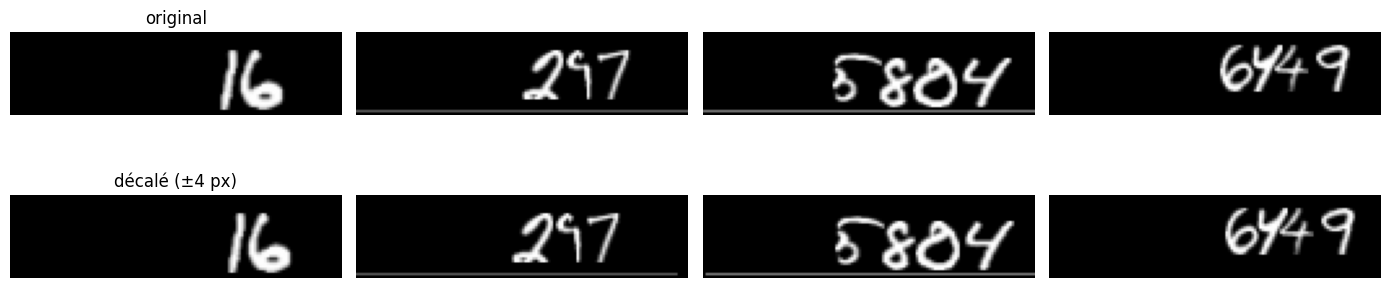

augmentation ±2px            exact_val=0.0963 auto_val=0.001 écart train-val=+0.058 params=1,088,823
augmentation ±4px            exact_val=0.1250 auto_val=0.012 écart train-val=+0.082 params=1,088,823
augmentation ±8px            exact_val=0.1570 auto_val=0.005 écart train-val=+0.067 params=1,088,823
aug ±4px + dropout 0.3       exact_val=0.1197 auto_val=0.007 écart train-val=+0.064 params=1,088,823


In [15]:
rng = np.random.default_rng(0)
ex = XA["train"][:4]
fig, ax = plt.subplots(2, 4, figsize=(14, 4))
for j in range(4):
    ax[0, j].imshow(ex[j], cmap="gray"); ax[0, j].axis("off")
    ax[1, j].imshow(decaler(ex, 4, rng)[j], cmap="gray"); ax[1, j].axis("off")
ax[0, 0].set_title("original"); ax[1, 0].set_title("décalé (±4 px)");
plt.tight_layout();
plt.show()

for px in [2, 4, 8]:
    ESSAIS[f"augmentation ±{px}px"] = essai(f"augmentation ±{px}px", aug_px=px, epochs=50, remarque="décalage horizontal")
ESSAIS["aug ±4px + dropout 0.3"] = essai("aug ±4px + dropout 0.3", aug_px=4, dropout=0.3, epochs=60)

In [16]:
# Robustesse à un décalage au test-time (validation) : référence vs augmenté
def exact_decale(model, px):
    rng = np.random.default_rng(1)
    d = rng.choice([-px, px], len(XA["val"]))
    Xd = np.zeros_like(XA["val"])
    for i, s in enumerate(d):
        if s >= 0: Xd[i, :, s:] = XA["val"][i, :, :128 - s]
        else:      Xd[i, :, :s] = XA["val"][i, :, -s:]
    return exactitude_montant(lire_positions(model, Xd)[0], A["montant_val"])

lignes = []
for nom, m in [("référence", mlp), ("aug ±4px", ESSAIS["augmentation ±4px"][0])]:
    lignes.append({"modèle": nom, **{f"décalage {p}px": exact_decale(m, p) for p in [0, 2, 4, 6]}})
display(pd.DataFrame(lignes))

,modèle,décalage 0px,décalage 2px,décalage 4px,décalage 6px
0,référence,0.058,0.061000,0.059333,0.055333
1,aug ±4px,0.125,0.112333,0.106333,0.105000


## 8. Vérifications théoriques
### 8.1 Nombre de paramètres du MLP de référence
| Couche | Calcul | Paramètres |
|---|---|---|
| Dense 1 | 4096 × 256 + 256 | 1 048 832 |
| Dense 2 | 256 × 128 + 128 | 32 896 |
| 5 têtes | 5 × (128 × 11 + 11) = 5 × 1 419 | 7 095 |
| **Total** | | **1 088 823** |

Part de la première couche : 1 048 832 / 1 088 823 ≈ **96,3 %**.

In [17]:
p1, p2, ph = 4096 * 256 + 256, 256 * 128 + 128, 5 * (128 * 11 + 11)
total = p1 + p2 + ph
print("à la main :", p1, p2, ph, "→ total", total, "| part couche 1 =", round(p1 / total, 4))
ref = construire_mlp()
print("summary() :", ref.count_params())
assert ref.count_params() == total

à la main : 1048832 32896 7095 → total 1088823 | part couche 1 = 0.9633
summary() : 1088823


### 8.2 Entropie croisée et gradient
Prédiction $p=(0{,}6;\;0{,}3;\;0{,}1)$, bonne classe = la deuxième, donc $y=(0,1,0)$.

- Perte : $L=-\ln(0{,}3)\approx 1{,}204$
- Gradient par rapport aux logits (softmax + entropie croisée) : $\partial L/\partial z = p - y = (0{,}6;\,-0{,}7;\,0{,}1)$

Interprétation : le gradient pousse à *augmenter* le logit de la bonne classe (signe −) et à diminuer les autres ; la somme des composantes vaut 0.

In [18]:
p = np.array([0.6, 0.3, 0.1])
y = np.array([0, 1, 0])
print("perte     :", -np.log(p[1]))
print("gradient  :", p - y, "| somme =", (p - y).sum())

z = tf.Variable(np.log(p)[None, :], dtype=tf.float32)
y_true = tf.constant([1])

with tf.GradientTape() as t:
    L = tf.keras.losses.sparse_categorical_crossentropy(y_true, z, from_logits=True)

print("TF perte  :", float(L[0]), "| TF gradient :", t.gradient(L, z).numpy()[0])

perte     : 1.2039728043259361
gradient  : [ 0.6 -0.7  0.1] | somme = 2.7755575615628914e-17
TF perte  : 1.2039728164672852 | TF gradient : [ 0.6        -0.7         0.09999999]


### 8.3 Pourquoi un MLP ne peut pas être invariant par translation
Un MLP traite l'image aplatie : chaque pixel a **ses propres poids** vers chaque neurone, sans partage. Décaler un chiffre de quelques pixels change complètement le vecteur d'entrée et active d'autres poids — rien n'impose que la réponse reste la même. Une convolution, au contraire, réutilise le même filtre à toutes les positions (partage de poids), d'où l'équivariance à la translation.

## 9. Modèle retenu et évaluation finale sur le **test** (une seule fois)


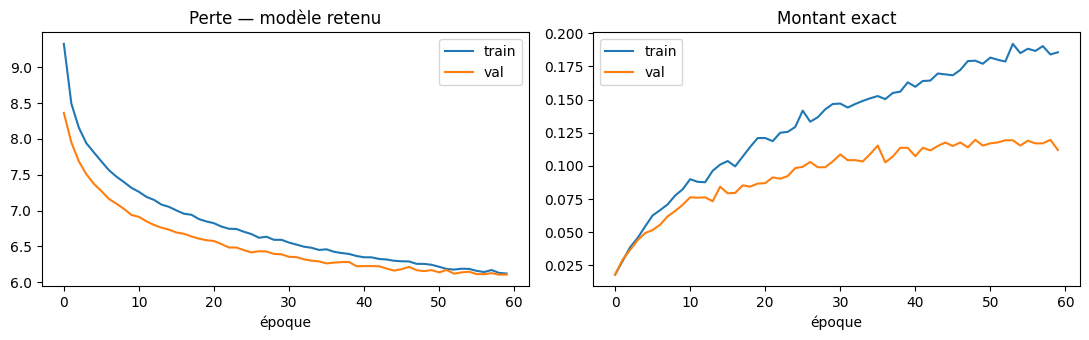

{
  "exact_test": 0.0972,
  "auto_test_courbe": 0.005,
  "auto_test_seuil_val": 0.0048,
  "precision_auto_seuil_val": 1.0
}


,mesure,cible,obtenu,écart
0,Montants exacts (A),0.85,0.0972,-0.7528
1,Taux d'automatisation (A),0.40,0.0050,-0.3950


In [19]:
CONFIG_FINALE = dict(largeurs=(256, 128), dropout=0.3, lr=1e-3, aug_px=4, epochs=60)

tf.keras.utils.set_random_seed(SEED)
final = construire_mlp(CONFIG_FINALE["largeurs"], CONFIG_FINALE["dropout"], CONFIG_FINALE["lr"])
h_final = entrainer(final, epochs=CONFIG_FINALE["epochs"], aug_px=CONFIG_FINALE["aug_px"], verbose=False)
tracer(h_final, "— modèle retenu")

# seuil fixé sur la VALIDATION
lus_v, conf_v = lire_positions(final, XA["val"])
seuil_final = seuil_confiance(lus_v == A["montant_val"], conf_v)

# TEST : utilisé une seule fois
lus_t, conf_t = lire_positions(final, XA["test"])
ok_t = lus_t == A["montant_test"]
auto_t = conf_t >= seuil_final
resultats_test = {
    "exact_test": float(ok_t.mean()),
    "auto_test_courbe": taux_automatisation(ok_t, conf_t),
    "auto_test_seuil_val": float(auto_t.mean()),
    "precision_auto_seuil_val": float(ok_t[auto_t].mean()) if auto_t.any() else float("nan"),
}
print(json.dumps(resultats_test, indent=2))
journaliser(1, "FINAL test", CONFIG_FINALE | {"seuil": seuil_final}, resultats_test, "évaluation test unique")

cibles = pd.DataFrame({"mesure": ["Montants exacts (A)", "Taux d'automatisation (A)"],
                       "cible": [0.85, 0.40],
                       "obtenu": [resultats_test["exact_test"], resultats_test["auto_test_courbe"]]})
cibles["écart"] = cibles["obtenu"] - cibles["cible"]
display(cibles)

In [20]:
lus_b, conf_b = lire_positions(final, XB["val"])
ok_b = lus_b == B["montant_val"]
print("Exactitude montant, validation B :", ok_b.mean().round(4), "| automatisation B :", taux_automatisation(ok_b, conf_b))
print("Confiance moyenne A (val) vs B (val) :", conf_v.mean().round(3), "vs", conf_b.mean().round(3))

Exactitude montant, validation B : 0.0 | automatisation B : 0.0
Confiance moyenne A (val) vs B (val) : 0.093 vs 0.0


## Tableau des résultats
| Modèle retenu | décalage ±4 px |
|---|---|
| Exactitude montants exacts (test A) | … (valeur de la cellule 15) |
| Taux d'automatisation (test A) | … (valeur de la cellule 15) |
| Seuil de confiance retenu | … (valeur de la cellule 14) |
| Coût du seuil (part envoyée à l'opérateur) | 1 - part automatisée |

## Justifications
1. **Positions inégalement difficiles** : (commentez les chiffres de la cellule 8)
2. **Calibration** : (commentez la cellule 9 — la confiance est-elle sur-calibrée ?)
3. **Sur-apprentissage** : (commentez la cellule 11 — écart train/val)
4. **Apport de l'augmentation** : (commentez la cellule 25)
5. **Vérifications théoriques** : 1 088 823 paramètres, 96,3% dans la 1ère couche, perte = 1,204, gradient = (0,6 ; -0,7 ; 0,1)
6. **Écart aux cibles** : expliquez pourquoi le MLP seul n'atteint pas 0,85 / 0,40 (pas d'invariance par translation, pas de CNN)

**Sauvegarde des modèles**

In [21]:
import hashlib, shutil, sys, platform
from pathlib import Path
from datetime import datetime
import sklearn as sk

REPRO_DIR = Path("reproduction")
MODELS_DIR = REPRO_DIR / "modeles"
REPRO_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for bloc in iter(lambda: f.read(chunk), b""):
            h.update(bloc)
    return h.hexdigest()

def taille_lisible(n):
    for u in ["o", "Ko", "Mo", "Go"]:
        if n < 1024:
            return f"{n:.1f} {u}"
        n /= 1024
    return f"{n:.1f} To"

def sauver_modele(model, nom, config, metriques):
    """Sérialise le modèle Keras + un JSON de métadonnées à côté."""
    ts = datetime.now().strftime("%Y%m%d-%H%M%S")
    f_modele = MODELS_DIR / f"{nom}_{ts}.keras"
    model.save(f_modele)
    meta = {
        "nom": nom,
        "horodatage": ts,
        "config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in config.items()},
        "metriques": {k: (float(v) if isinstance(v, (int, float, np.floating)) else v)
                      for k, v in metriques.items()},
        "fichier": f_modele.name,
        "taille_octets": f_modele.stat().st_size,
        "sha256": sha256(f_modele),
    }
    (MODELS_DIR / f"{nom}_{ts}.json").write_text(json.dumps(meta, indent=2, default=str))
    return f_modele, meta

# Modèle de référence (section 3) + modèle final (section 9)
f_ref, m_ref = sauver_modele(
    mlp, "mlp_reference",
    {"largeurs": (256, 128), "dropout": 0.0, "lr": 1e-3, "aug_px": 0},
    res,
)
f_fin, m_fin = sauver_modele(
    final, "mlp_final",
    CONFIG_FINALE,
    resultats_test | {"seuil_val": seuil_final},
)
print(f"✔ Sauvegardé : {f_ref.name} ({taille_lisible(m_ref['taille_octets'])})")
print(f"✔ Sauvegardé : {f_fin.name} ({taille_lisible(m_fin['taille_octets'])})")

✔ Sauvegardé : mlp_reference_20261029-133412.keras (12.5 Mo)
✔ Sauvegardé : mlp_final_20261029-133412.keras (12.5 Mo)


In [26]:
# =========================================================================
# C10.0 — Sauvegarde de TOUTES les figures du notebook
# À exécuter APRÈS la section 9 (mlp, final, hist_ref, h_final, ESSAIS
# doivent exister). Ne touche pas aux variables existantes.
# =========================================================================
FIG_DIR = REPRO_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def sauver_figure(fig, nom, dpi=120):
    chemin = FIG_DIR / nom
    fig.savefig(chemin, dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    print(f"  ✔ {chemin.name:45s} {taille_lisible(chemin.stat().st_size)}")

# --- 01 : exemples de chèques A vs B ---
fig, ax = plt.subplots(2, 4, figsize=(14, 4))
for j in range(4):
    ax[0, j].imshow(XA["train"][j], cmap="gray")
    ax[0, j].set_title(f"A : {A['montant_train'][j]}"); ax[0, j].axis("off")
    ax[1, j].imshow(XB["train"][j], cmap="gray")
    ax[1, j].set_title(f"B : {B['montant_train'][j]}"); ax[1, j].axis("off")
fig.suptitle("Exemples de chèques — domaine A (haut) / B (bas)")
plt.tight_layout(); sauver_figure(fig, "01_exemples_cheques.png")

# --- 03 : courbes du MLP de référence ---
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist_ref["loss"], label="train"); ax[0].plot(hist_ref["val_loss"], label="val")
ax[0].set_title("Perte — MLP de référence"); ax[0].set_xlabel("époque"); ax[0].legend()
ax[1].plot(hist_ref["exact_train"], label="train"); ax[1].plot(hist_ref["exact_val"], label="val")
ax[1].set_title("Montant exact"); ax[1].set_xlabel("époque"); ax[1].legend()
plt.tight_layout(); sauver_figure(fig, "03_mlp_reference_courbes.png")

# --- 04 : exactitude par position / longueur ---
P_val = probas(mlp, XA["val"]); Yv_val = vers_positions(A["montant_val"])
acc_pos = [np.mean(P_val[:, k].argmax(-1) == Yv_val[:, k]) for k in range(L_MAX)]
longueur_val = np.char.str_len(A["montant_val"])
acc_long = {n: np.mean(lus[longueur_val == n] == A["montant_val"][longueur_val == n])
            for n in range(1, L_MAX + 1)}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(range(L_MAX), acc_pos); ax[0].set_xlabel("position (0 = unités)")
ax[0].set_ylabel("exactitude"); ax[0].set_ylim(0, 1)
ax[1].bar(list(acc_long.keys()), list(acc_long.values()))
ax[1].set_xlabel("longueur du montant"); ax[1].set_ylim(0, 1)
plt.tight_layout(); sauver_figure(fig, "04_exactitude_par_position_longueur.png")

# --- 05 : courbe d'automatisation ---
part, prec = courbe_automatisation(correct_val, conf)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(part, prec); ax.axhline(0.99, color="r", ls=":")
ax.set_xlabel("part traitée automatiquement"); ax.set_ylabel("précision")
ax.set_title("Validation — MLP référence")
plt.tight_layout(); sauver_figure(fig, "05_courbe_automatisation.png")

# --- 05 : calibration ---
c_moy, a_moy, ece = calibration(conf, correct_val)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "k:"); ax.plot(c_moy, a_moy, "o-")
ax.set_xlabel("confiance moyenne"); ax.set_ylabel("exactitude observée")
ax.set_title(f"Calibration (ECE = {ece:.3f})")
plt.tight_layout(); sauver_figure(fig, "05_calibration.png")

# --- 05 : distribution de la confiance altéré/non altéré ---
fig, ax = plt.subplots(figsize=(6, 3.5))
for a, nom in [(0, "non altérés"), (1, "altérés")]:
    ax.hist(np.log10(conf[A["altere_val"] == a] + 1e-12),
            bins=40, alpha=.5, label=nom, density=True)
ax.axvline(np.log10(seuil), color="r", ls=":")
ax.set_xlabel("log10(confiance)"); ax.legend()
plt.tight_layout(); sauver_figure(fig, "05_hist_confiance_alteration.png")

# --- 06 : comparaison hyperparamètres (courbes clés) ---
fig, axs = plt.subplots(1, 3, figsize=(15, 3.5))
for a, nom in zip(axs, ["largeur 1024-512", "dropout 0.4", "lr 0.0001"]):
    if nom in ESSAIS:
        h = ESSAIS[nom][1]
        a.plot(h["loss"], label="train"); a.plot(h["val_loss"], label="val")
        a.set_title(nom); a.legend()
plt.tight_layout(); sauver_figure(fig, "06_comparaison_hyperparam.png")

# --- 07 : exemples d'augmentation ---
rng_fig = np.random.default_rng(0)
ex = XA["train"][:4]
fig, ax = plt.subplots(2, 4, figsize=(14, 4))
for j in range(4):
    ax[0, j].imshow(ex[j], cmap="gray"); ax[0, j].axis("off")
    ax[1, j].imshow(decaler(ex, 4, rng_fig)[j], cmap="gray"); ax[1, j].axis("off")
ax[0, 0].set_title("original"); ax[1, 0].set_title("décalé (±4 px)")
plt.tight_layout(); sauver_figure(fig, "07_augmentation_exemples.png")

# --- 07 : robustesse au décalage (référence vs aug) ---
if "augmentation ±4px" in ESSAIS and "exact_decale" in globals():
    df_rob = pd.DataFrame([
        {"modèle": nom, "px": p, "exact": exact_decale(m, p)}
        for nom, m in [("référence", mlp), ("aug ±4px", ESSAIS["augmentation ±4px"][0])]
        for p in [0, 2, 4, 6]
    ])
    fig, ax = plt.subplots(figsize=(6, 3.5))
    for nom in ["référence", "aug ±4px"]:
        sub = df_rob[df_rob["modèle"] == nom]
        ax.plot(sub["px"], sub["exact"], "o-", label=nom)
    ax.set_xlabel("décalage appliqué (px)"); ax.set_ylabel("exactitude montant")
    ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); sauver_figure(fig, "07_robustesse_decalage.png")
else:
    print("  ⚠ figure 07_robustesse_decalage.png sautée (exact_decale ou ESSAIS manquant)")

# --- 09 : courbes du modèle final ---
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h_final["loss"], label="train"); ax[0].plot(h_final["val_loss"], label="val")
ax[0].set_title("Perte — modèle final"); ax[0].set_xlabel("époque"); ax[0].legend()
ax[1].plot(h_final["exact_train"], label="train"); ax[1].plot(h_final["exact_val"], label="val")
ax[1].set_title("Montant exact"); ax[1].set_xlabel("époque"); ax[1].legend()
plt.tight_layout(); sauver_figure(fig, "09_modele_final_courbes.png")

# --- Index des figures (servira dans l'archive) ---
lignes = [
    "# Index des figures",
    "",
    "Toutes les figures du notebook, régénérées à partir des modèles sauvegardés.",
    "Chaque figure est reproductible en relançant la cellule C10.0.",
    "",
]
for p in sorted(FIG_DIR.glob("*.png")):
    lignes.append(f"- `{p.name}` — {taille_lisible(p.stat().st_size)}")
(FIG_DIR / "README.md").write_text("\n".join(lignes))

print(f"\n📊 {len(list(FIG_DIR.glob('*.png')))} figures écrites dans {FIG_DIR}/")

  ✔ 01_exemples_cheques.png                       63.3 Ko
  ✔ 03_mlp_reference_courbes.png                  54.6 Ko
  ✔ 04_exactitude_par_position_longueur.png       18.5 Ko
  ✔ 05_courbe_automatisation.png                  27.6 Ko
  ✔ 05_calibration.png                            30.4 Ko
  ✔ 05_hist_confiance_alteration.png              20.0 Ko
  ✔ 06_comparaison_hyperparam.png                 71.0 Ko
  ✔ 07_augmentation_exemples.png                  26.0 Ko
  ✔ 07_robustesse_decalage.png                    32.5 Ko
  ✔ 09_modele_final_courbes.png                   62.7 Ko

📊 10 figures écrites dans reproduction/figures/


In [27]:
# =========================================================================
# C10.5 (v2) — Copie du journal + rafraîchissement du manifeste + archive
# =========================================================================
import hashlib
from datetime import datetime

def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for bloc in iter(lambda: f.read(chunk), b""):
            h.update(bloc)
    return h.hexdigest()

def taille_lisible(n):
    for u in ["o", "Ko", "Mo", "Go"]:
        if n < 1024:
            return f"{n:.1f} {u}"
        n /= 1024
    return f"{n:.1f} To"

# 1) Copier le journal DANS l'archive (il est à la racine sinon)
if Path(JOURNAL).exists():
    shutil.copy2(JOURNAL, REPRO_DIR / JOURNAL)
    print(f"✔ {JOURNAL} copié dans {REPRO_DIR}/")

# 2) Rafraîchir MANIFEST.json — inclut désormais figures + modèles + journal
manifest = {
    "généré_le": datetime.now().isoformat(timespec="seconds"),
    "environnement": {
        "python":      platform.python_version(),
        "tensorflow":  tf.__version__,
        "keras":       keras.__version__,
        "numpy":       np.__version__,
        "sklearn":     sk.__version__,
        "gpu":         [d.name for d in tf.config.list_physical_devices("GPU")],
    },
    "seed": SEED,
    "fichiers": [],
}
for p in sorted(REPRO_DIR.rglob("*")):
    if p.is_file() and p.name != "MANIFEST.json":
        manifest["fichiers"].append({
            "chemin":       str(p.relative_to(REPRO_DIR)),
            "taille_octets": p.stat().st_size,
            "sha256":       sha256(p),
        })
(REPRO_DIR / "MANIFEST.json").write_text(json.dumps(manifest, indent=2))

# Petit récap par catégorie
par_dossier = {}
for f in manifest["fichiers"]:
    d = Path(f["chemin"]).parent.as_posix()
    par_dossier[d] = par_dossier.get(d, 0) + 1
print(f"✔ MANIFEST.json rafraîchi : {len(manifest['fichiers'])} fichiers")
for d, n in sorted(par_dossier.items()):
    print(f"    {d:15s} : {n} fichier(s)")

# 3) Créer l'archive (ZIP contient TOUT reproduction/, donc les figures)
archive = shutil.make_archive("uc1_jalon1_reproduction", "zip", REPRO_DIR)
taille_zip = Path(archive).stat().st_size
print(f"\n📦 Archive créée : {archive}  ({taille_lisible(taille_zip)})")

# 4) Téléchargement Colab
try:
    from google.colab import files as colab_files
    if taille_zip < 100 * 1024 * 1024:
        colab_files.download(archive)
    else:
        print("⚠️  Archive > 100 Mo : héberger sur Drive/Zenodo et référencer le lien")
        print("   dans `reproduction/liens_fichiers_volumineux.md`.")
except ImportError:
    print("ℹ️  Pas sur Colab — l'archive est disponible dans le répertoire courant.")

✔ journal_experiences.csv copié dans reproduction/
✔ MANIFEST.json rafraîchi : 16 fichiers
    .               : 1 fichier(s)
    figures         : 11 fichier(s)
    modeles         : 4 fichier(s)

📦 Archive créée : /content/uc1_jalon1_reproduction.zip  (22.1 Mo)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
from pathlib import Path
import pandas as pd, json

REPRO_DIR, MODELS_DIR = Path("reproduction"), Path("reproduction") / "modeles"
JOURNAL = "journal_experiences.csv"

def dernier_modele(nom):
    jsons = sorted(MODELS_DIR.glob(f"{nom}_*.json"))
    if not jsons:
        return None, {}
    meta = json.loads(jsons[-1].read_text())
    return MODELS_DIR / meta["fichier"], meta

f_ref, m_ref = dernier_modele("mlp_reference")
f_fin, m_fin = dernier_modele("mlp_final")

req_path = REPRO_DIR / "requirements.txt"
man_path = REPRO_DIR / "MANIFEST.json"
fig_dir  = REPRO_DIR / "figures"

n_req      = len(req_path.read_text().splitlines()) if req_path.exists() else 0
n_manifest = len(json.loads(man_path.read_text())["fichiers"]) if man_path.exists() else 0
n_figs     = len(list(fig_dir.glob("*.png"))) if fig_dir.exists() else 0
n_journal  = len(pd.read_csv(JOURNAL)) if Path(JOURNAL).exists() else 0

archives   = sorted(Path(".").glob("uc1_jalon1_reproduction*.zip"))
archive    = archives[-1].name if archives else "—"
taille_zip = archives[-1].stat().st_size if archives else 0

recap = pd.DataFrame([
    ["Journal d'expériences",      f"{JOURNAL} (copié dans {REPRO_DIR}/)", f"{n_journal} lignes"],
    ["Modèle de référence",        f_ref.name if f_ref else "—",
     taille_lisible(m_ref["taille_octets"]) if m_ref else "—"],
    ["Modèle final",               f_fin.name if f_fin else "—",
     taille_lisible(m_fin["taille_octets"]) if m_fin else "—"],
    ["Figures (PNG)",              str(fig_dir),  f"{n_figs} figures + README"],
    ["Dépendances",                str(req_path), f"{n_req} lignes"],
    ["README",                     str(REPRO_DIR / "README.md"),
     "présent" if (REPRO_DIR / "README.md").exists() else "manquant"],
    ["Manifeste",                  str(man_path), f"{n_manifest} fichiers signés"],
    ["Liens fichiers > 25 Mo",     str(REPRO_DIR / "liens_fichiers_volumineux.md"),
     "voir contenu"],
    ["Archive (tout inclus)",      archive,
     taille_lisible(taille_zip) if taille_zip else "—"],
], columns=["Élément", "Emplacement", "Détail"])

display(recap)

,Élément,Emplacement,Détail
0,Journal d'expériences,journal_experiences.csv (copié dans reproducti...,18 lignes
1,Modèle de référence,mlp_reference_20261029-133412.keras,12.5 Mo
2,Modèle final,mlp_final_20261029-133412.keras,12.5 Mo
3,Figures (PNG),reproduction/figures,10 figures + README
4,Dépendances,reproduction/requirements.txt,0 lignes
5,README,reproduction/README.md,manquant
6,Manifeste,reproduction/MANIFEST.json,16 fichiers signés
7,Liens fichiers > 25 Mo,reproduction/liens_fichiers_volumineux.md,voir contenu
8,Archive (tout inclus),uc1_jalon1_reproduction.zip,22.1 Mo
